**[🏠 Course Home](00_START_HERE.ipynb)** | **🤖 [AI-Native](../ai/21_framework_reliability_and_tolerance_contracts.ipynb)** | **📖 [Conceptual](../conceptual/21_framework_reliability_and_tolerance_contracts.ipynb)** | **🐍 [Python](../python/21_framework_reliability_and_tolerance_contracts.ipynb)** | **⬅️ [Prev: Ch 20: CI/CD Test Promotion Gatekeeping](20_test_promotion_heuristics_vs_bayes.ipynb)** | **➡️ [Next: Ch 22: Foundations of Information Theory](22_foundations_of_information_theory.ipynb)**

*🧭 Part V: Production Reliability, CI/CD & Active Learning — Chapter 21 of 23*

---

# Chapter 21: Framework Reliability & Tolerable Flakiness — The Two-Tier Tolerance Contract
### *Serial Compounding, The Plug-In Fallacy, and Qualifying Test Harnesses in Base R*

In this R companion sheet, we implement the **Two-Tier Tolerance Guarantee** for testing frameworks using native R simulation tools (`rbeta`, `rbinom`, and vectorization).

---

## Table of Contents
1. **Part 1: The Serial Multiplier (The Math of Suite Collapse)**
2. **Part 2: The Two-Tier Posterior Predictive Engine in R**
3. **Part 3: Wald's Sequential Probability Ratio Test (SPRT) under Stress**
4. **Part 4: False Discovery Rate (FDR) Analysis**

---

## Part 1: The Serial Multiplier & Weakest-Link Reliability Chains (The Math of Suite Collapse)

### 1.1 The "99.9% Reliable" Fallacy
In standard software engineering, a $99.9\%$ pass rate ($	heta = 0.001$, or 1 failure in 1,000 executions) sounds like enterprise-grade quality. If an engineer runs a single test locally, it will succeed $99.9\%$ of the time.

However, in modern Continuous Integration (CI/CD) pipelines, tests do not run in isolation—they operate in a **strict serial dependency chain**. If **any single test fails**, the entire build/pull-request turns 🔴 **RED**, blocking deployment:

```text
                       THE SERIAL CHAIN OF A CI BUILD (K = 1,000 Tests)

   Test 1          Test 2          Test 3                       Test 999        Test 1,000
  ┌─────────┐     ┌─────────┐     ┌─────────┐                  ┌─────────┐     ┌─────────┐
  │  Pass   ├────►│  Pass   ├────►│  FAIL   ├───[ BUILD DEAD ]─►   ???   ├────►│   ???   │
  └─────────┘     └─────────┘     └─────────┘     (PR Blocked) └─────────┘     └─────────┘
    (1 - θ)    ×    (1 - θ)    ×    (1 - θ)         ×   ...   ×    (1 - θ)
```

If each test invocation has a framework failure probability $	heta$, overall **Suite Survival** $R_{\text{suite}}$ across $K$ serial tests is governed by the binomial product:

$$R_{\text{suite}} = \prod_{k=1}^K (1 - \theta_k) \approx (1 - \theta)^K \approx e^{-K\theta}$$

When leadership specifies an apparently strict SLA of "flakiness under 0.1%" ($\theta = 0.001$) on a suite of $K = 1{,}000$ tests:

$$R_{\text{suite}} = (1 - 0.001)^{1{,}000} \approx 0.367 \quad (\mathbf{36.7\% \text{ Suite Pass Rate}})$$

> **The Weakest-Link Reality**: Even though every single test is individually 99.9% reliable, **over 63% of all PR builds will turn RED purely due to infrastructure noise!**  
> Developers lose trust in CI, merge queues stall, and teams waste thousands of developer-hours clicking "Rerun Failed Jobs".

---

### 1.2 The Serial Compounding Landscape
Reliability in serial chains does not average; **it multiplies**. The table below demonstrates the catastrophic compounding across different suite scales:

| Single-Test Reliability ($1 - \theta$) | Flake Rate ($\theta$) | Suite Survival ($K = 100$) | Suite Survival ($K = 1{,}000$) | Suite Survival ($K = 5{,}000$) |
| :--- | :--- | :--- | :--- | :--- |
| **$99.0\%$** | $1.0 \times 10^{-2}$ | $36.6\%$ | $\approx 0.004\%$ | $\approx 0.000\%$ (Permanent Red) |
| **$99.9\%$** | $1.0 \times 10^{-3}$ | $90.5\%$ | **$36.7\%$** | $0.67\%$ |
| **$99.99\%$** | $1.0 \times 10^{-4}$ | $99.0\%$ | $90.5\%$ | $60.6\%$ |
| **$99.999\%$** | $1.0 \times 10^{-5}$ | $99.9\%$ | $99.0\%$ | $\mathbf{95.1\%}$ |

---

### 1.3 Architectural Asymmetry: Applications vs. Testing Frameworks
Why must foundational test frameworks (browser drivers, socket mocks, database containers) meet dramatically higher standards than application code?
* **Application Tests**: Test a single isolated code path (e.g. `test_user_checkout`). If one test is flaky, it causes at most 1 failure opportunity per PR.
* **Testing Frameworks**: Sit at the **root of the entire dependency graph**. The framework executes beneath *every single test* from Test 1 to Test $K$. 
* Consequently, a framework bug with a tiny flake probability of $	heta = 10^{-4}$ does not execute once—it executes $K$ times per PR, compounding into an unacceptable suite failure rate.

Let us now simulate and visualize suite survival curves across realistic test suite sizes ($K = 50$ to $3{,}000$) and varying framework flake rates.



=== Suite-Level Survival at K = 1,000 Tests ===


θ = 0.01000 -> Suite Survival =   0.00% | Expected Framework Red Builds = 100.00%
θ = 0.00100 -> Suite Survival =  36.77% | Expected Framework Red Builds =  63.23%
θ = 0.00010 -> Suite Survival =  90.48% | Expected Framework Red Builds =   9.52%
θ = 0.00001 -> Suite Survival =  99.00% | Expected Framework Red Builds =   1.00%


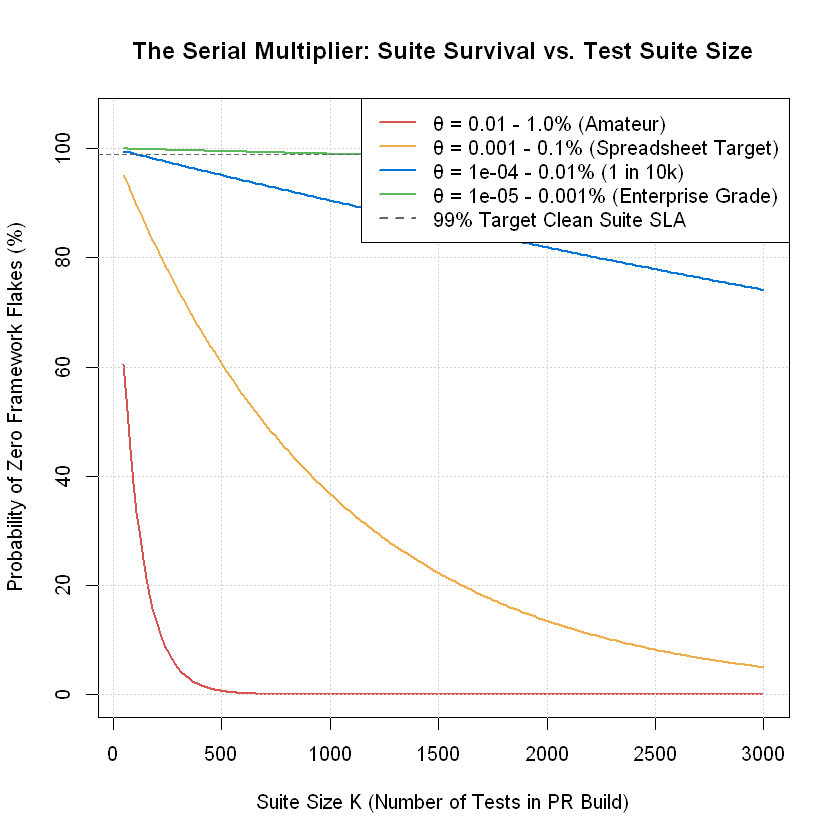

In [1]:
# Suite survival curves across K and theta
K_values <- seq(50, 3000, length.out = 200)
thetas <- c(0.01, 0.001, 0.0001, 0.00001)
labels <- c("1.0% (Amateur)", "0.1% (Spreadsheet Target)", "0.01% (1 in 10k)", "0.001% (Enterprise Grade)")
colors <- c("#d9534f", "#f0ad4e", "#0275d8", "#5cb85c")

plot(K_values, (1 - thetas[1])^K_values * 100, type = "l", col = colors[1], lwd = 2,
     ylim = c(0, 105), xlim = c(50, 3000),
     xlab = "Suite Size K (Number of Tests in PR Build)",
     ylab = "Probability of Zero Framework Flakes (%)",
     main = "The Serial Multiplier: Suite Survival vs. Test Suite Size")
grid()

for (i in 2:length(thetas)) {
  lines(K_values, (1 - thetas[i])^K_values * 100, col = colors[i], lwd = 2)
}
abline(h = 99, lty = 2, col = "gray40", lwd = 1.5)

legend("topright", legend = c(paste("θ =", thetas, "-", labels), "99% Target Clean Suite SLA"),
       col = c(colors, "gray40"), lty = c(rep(1, 4), 2), lwd = 2, bg = "white")

cat("=== Suite-Level Survival at K = 1,000 Tests ===\n")
for (i in 1:length(thetas)) {
  r <- (1 - thetas[i])^1000
  cat(sprintf("θ = %.5f -> Suite Survival = %6.2f%% | Expected Framework Red Builds = %6.2f%%\n",
              thetas[i], r * 100, (1 - r) * 100))
}

## Part 2: The Two-Tier Posterior Predictive Engine in R

We implement `evaluate_framework_qualification` in R using `rbeta()` and `rbinom()`.

In [2]:
evaluate_framework_qualification <- function(n_benchmarks, k_failures, K_suite_size = 1000, n_sims = 100000, alpha_prior = 1, beta_prior = 1) {
  # 1. Posterior draws for theta
  a_post <- alpha_prior + k_failures
  b_post <- beta_prior + n_benchmarks - k_failures
  theta_draws <- rbeta(n_sims, a_post, b_post)
  
  # 2. Tier 2: Parameter tolerance bound P(theta <= 1e-5)
  p_theta_sub_1e5 <- mean(theta_draws <= 1e-5)
  
  # 3. Tier 1: Suite-level posterior predictive simulation
  suite_flakes <- rbinom(n_sims, size = K_suite_size, prob = theta_draws)
  p_clean_suite <- mean(suite_flakes == 0)
  
  return(list(
    n_benchmarks = n_benchmarks,
    k_failures = k_failures,
    theta_median = median(theta_draws),
    p_theta_sub_1e5 = p_theta_sub_1e5,
    p_clean_suite = p_clean_suite,
    tier1_pass = p_clean_suite >= 0.99,
    tier2_pass = p_theta_sub_1e5 >= 0.95
  ))
}

scenarios <- list(
  list(n = 500, k = 0, desc = "Small Benchmark (500 runs, 0 flakes)"),
  list(n = 5000, k = 0, desc = "Medium Benchmark (5,000 runs, 0 flakes)"),
  list(n = 100000, k = 0, desc = "Rigorous Benchmark (100,000 runs, 0 flakes)"),
  list(n = 100000, k = 1, desc = "Realistic Scale (100,000 runs, 1 flake)")
)

cat(sprintf("%-42s | %-22s | %-7s | %-15s | %s\n",
            "Scenario", "P(Clean Suite >= 99%)", "Tier 1", "P(θ <= 1e-5)", "Tier 2"))
cat(paste(rep("-", 105), collapse = ""), "\n")

for (s in scenarios) {
  res <- evaluate_framework_qualification(s$n, s$k, K_suite_size = 1000)
  t1 <- if (res$tier1_pass) "PASS" else "FAIL"
  t2 <- if (res$tier2_pass) "PASS" else "FAIL"
  cat(sprintf("%-42s | %6.2f%% (Target: >=99%%) | %-7s | %6.2f%%          | %s\n",
              s$desc, res$p_clean_suite * 100, t1, res$p_theta_sub_1e5 * 100, t2))
}

Scenario                                   | P(Clean Suite >= 99%)  | Tier 1  | P(θ <= 1e-5)   | Tier 2


--------------------------------------------------------------------------------------------------------- 


Small Benchmark (500 runs, 0 flakes)       |  33.09% (Target: >=99%) | FAIL    |   0.50%          | FAIL
Medium Benchmark (5,000 runs, 0 flakes)    |  83.32% (Target: >=99%) | FAIL    |   4.79%          | FAIL
Rigorous Benchmark (100,000 runs, 0 flakes) |  99.09% (Target: >=99%) | PASS    |  63.12%          | FAIL
Realistic Scale (100,000 runs, 1 flake)    |  98.00% (Target: >=99%) | FAIL    |  26.62%          | FAIL


## Part 3: Wald's Sequential Probability Ratio Test (SPRT) in R

In [3]:
theta_0 <- 0.001
theta_1 <- 0.05
alpha_risk <- 0.01
beta_risk <- 0.01

A_threshold <- log((1 - beta_risk) / alpha_risk)
B_threshold <- log(beta_risk / (1 - alpha_risk))

set.seed(42)
true_stress_rate <- 0.04
log_llr <- 0.0
step <- 0

while (log_llr < A_threshold && log_llr > B_threshold && step < 200) {
  step <- step + 1
  outcome <- if (runif(1) < true_stress_rate) 1 else 0
  llr_step <- if (outcome == 1) log(theta_1 / theta_0) else log((1 - theta_1) / (1 - theta_0))
  log_llr <- log_llr + llr_step
}

cat(sprintf("SPRT under Stress: Evaluated in %d test runs!\n", step))
if (log_llr >= A_threshold) {
  cat(sprintf("❌ REJECTED at run %d: Flakiness detected! Saved >99%% of benchmark compute.\n", step))
} else if (log_llr <= B_threshold) {
  cat(sprintf("✅ CERTIFIED at run %d: Passed stress criteria!\n", step))
}

SPRT under Stress: Evaluated in 37 test runs!


❌ REJECTED at run 37: Flakiness detected! Saved >99% of benchmark compute.


---

## Part 4: Business Economics & False Discovery Rate (FDR)

In production software engineering, test failures are actionable signals.
When a build turns red, an on-call engineer investigates, pauses a rollout,
or rejects a pull request.

However, the real business damage of framework flakiness is quantified by the
**False Discovery Rate (FDR)**:
$$\text{FDR} = \frac{P(\text{Flake})}{P(\text{Bug}) + P(\text{Flake})}$$

Where:
* $P(\text{Bug})$ is the prior probability that a pull request contains a
  genuine code regression (typically $1\%\text{--}5\%$).
* $P(\text{Flake}) = 1 - (1 - \theta)^K$ is the probability that the
  framework produces at least one false-red test failure across $K$ tests.

Even if an engineer writes a "clean" PR, a high-flakiness framework can turn
most observed red builds into false alarms, destroying developer trust.

=== Framework Reliability & False Discovery Rate (FDR) ===


θ = 0.00100 -> False-Red Builds = 63.23% | FDR = 96.93% of failed builds are lies!
θ = 0.00010 -> False-Red Builds =  9.52% | FDR = 82.63% of failed builds are lies!
θ = 0.00001 -> False-Red Builds =  1.00% | FDR = 33.22% of failed builds are lies!


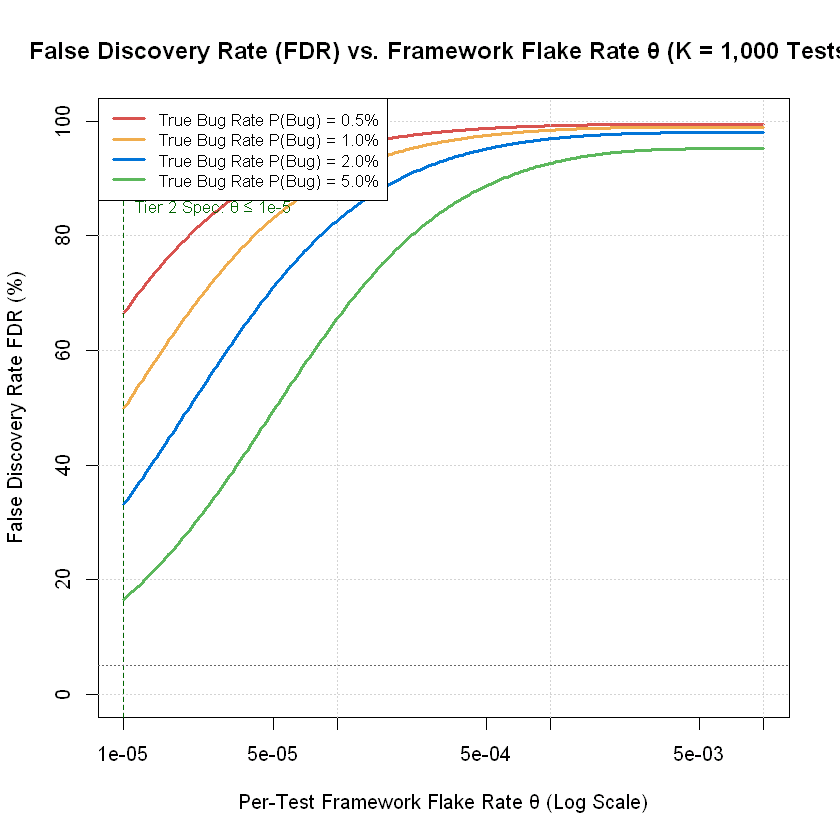

In [4]:
# Business Economics & False Discovery Rate (FDR) across Framework Tiers
calculate_fdr <- function(p_true_bug, p_framework_red) {
  p_framework_red / (p_true_bug + p_framework_red)
}

p_bug <- 0.02  # 2% of PRs have genuine application code regressions
thetas <- c(0.001, 0.0001, 0.00001)

cat("=== Framework Reliability & False Discovery Rate (FDR) ===\n")
for (th in thetas) {
  r_suite <- (1 - th)^1000
  p_flake_red <- 1 - r_suite
  fdr <- calculate_fdr(p_bug, p_flake_red)
  cat(sprintf("θ = %.5f -> False-Red Builds = %5.2f%% | FDR = %5.2f%% of failed builds are lies!\n",
              th, p_flake_red * 100, fdr * 100))
}

# Plot FDR vs Theta across different application bug rates
theta_seq <- 10^seq(-5, -2, length.out = 300)
p_bugs <- c(0.005, 0.01, 0.02, 0.05)
colors <- c("#d9534f", "#f0ad4e", "#0275d8", "#5cb85c")

plot(theta_seq, calculate_fdr(p_bugs[1], 1 - (1 - theta_seq)^1000) * 100,
     type = "l", log = "x", col = colors[1], lwd = 2.4, ylim = c(0, 100),
     xlab = "Per-Test Framework Flake Rate θ (Log Scale)",
     ylab = "False Discovery Rate FDR (%)",
     main = "False Discovery Rate (FDR) vs. Framework Flake Rate θ (K = 1,000 Tests)")
grid()

for (i in 2:length(p_bugs)) {
  lines(theta_seq, calculate_fdr(p_bugs[i], 1 - (1 - theta_seq)^1000) * 100,
        col = colors[i], lwd = 2.4)
}

abline(v = 1e-5, col = "darkgreen", lty = 2, lwd = 1.5)
abline(h = 5, col = "gray40", lty = 3, lwd = 1.5)
text(1e-5, 85, "Tier 2 Spec: θ ≤ 1e-5", pos = 4, col = "darkgreen", cex = 0.85)

legend("topleft", legend = sprintf("True Bug Rate P(Bug) = %.1f%%", p_bugs * 100),
       col = colors, lty = 1, lwd = 2.4, bg = "white", cex = 0.85)

## Summary & Architecture Contract Template

| Component | Recommended Specification | Rationale |
| :--- | :--- | :--- |
| **Tier 1 (SLA)** | $\mathbb{P}(\tilde{Y} = 0) \ge 99.0\%$ across $K = 1{,}000$ | Put in developer RFCs; defines the user experience. |
| **Tier 2 (Acceptance)** | $\mathbb{P}(\theta \le 1.0 \times 10^{-5}) \ge 95.0\%$ | Put in CI benchmark assertions; defines the test bar. |
| **Qualification** | Shake Table (CPU/jitter injection) + SPRT | Qualifies framework in $< 200$ runs instead of $100{,}000$ runs. |

---



---

## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Sharpen your intuition and practice the mathematical concepts introduced in
this sheet. Write your solutions in the interactive attempt cells below before
expanding the verified solutions.

---

### 🟢 Tier 1 (Warm-Up): Serial Compounding & Clean Suite Probability
> **Scenario**: A continuous integration test suite executes $K = 500$
> independent tests on every commit. The testing framework has a per-test
> transient error probability $\theta = 0.0002$ ($0.02\%$).
>
> 1. What is the probability $R_{\text{suite}} = (1 - \theta)^K$ that the
>    entire suite runs with zero framework errors?
> 2. What is the expected percentage of builds that turn red purely due to
>    framework noise?
> 3. If a team merges 100 PRs per day, how many daily PR builds are broken by
>    framework false alarms?

In [5]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
K_tests <- 500
theta_flake <- 0.0002

# 1. Clean suite probability:
# r_suite <- (1 - theta_flake)^K_tests

# 2. False-red build probability:
# p_false_red <- 1 - r_suite

# 3. Daily broken builds across 100 PRs:
# daily_broken <- 100 * p_false_red

# cat(sprintf("Suite Survival: %.2f%%\n", r_suite * 100))
# cat(sprintf("False Red Rate: %.2f%%\n", p_false_red * 100))
# cat(sprintf("Daily False Red Builds: %.1f\n", daily_broken))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
1. **Clean Suite Probability**:
   $$R_{\text{suite}} = (1 - 0.0002)^{500} = 0.9998^{500} \approx 0.9048 = \mathbf{90.5\%}$$
2. **False Red Build Probability**:
   $$P(\text{Flake Red}) = 1 - 0.9048 = \mathbf{9.52\%}$$
3. **Daily Impact**:
   $$100 \times 0.0952 \approx \mathbf{9.5 \text{ broken builds per day}}$$
   Even with a seemingly tiny per-test flake rate ($0.02\%$), nearly **1 out of
   every 10 builds** is derailed by framework false alarms!

</details>

---

### 🟡 Tier 2 (Guided Calculation): Two-Tier Qualification with Beta-Binomial
> **Scenario**: The infrastructure team runs $N = 20{,}000$ benchmark runs of
> the framework harness in an isolated staging cluster and observes $k = 0$
> failures.
>
> 1. Parameterize the posterior $\theta \sim \text{Beta}(\alpha_0 + k, \beta_0 + n - k)$
>    starting from a flat prior $\text{Beta}(1, 1)$.
> 2. Draw $100{,}000$ Monte Carlo samples from the posterior with `rbeta()`.
> 3. Evaluate Tier 2: Does $P(\theta \le 10^{-5}) \ge 95\%$ pass?
> 4. For a suite size of $K = 1{,}000$ tests, draw posterior predictive suite
>    outcomes with `rbinom()`.
> 5. Evaluate Tier 1: Does $P(\text{Clean Suite}) \ge 99\%$ pass?

In [6]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
set.seed(42)
n_benchmarks <- 20000
k_failures <- 0
K_suite <- 1000
n_sims <- 100000

# 1. Posterior parameters:
# a_post <- 1 + k_failures
# b_post <- 1 + n_benchmarks - k_failures

# 2. Posterior draws:
# theta_draws <- rbeta(n_sims, a_post, b_post)

# 3. Tier 2 check P(theta <= 1e-5):
# p_tier2 <- mean(theta_draws <= 1e-5)

# 4. Tier 1 check P(Clean Suite):
# suite_flakes <- rbinom(n_sims, size = K_suite, prob = theta_draws)
# p_tier1 <- mean(suite_flakes == 0)

# cat(sprintf("Tier 2 P(theta <= 1e-5): %.2f%% (Pass >= 95%%: %s)\n",
#             p_tier2 * 100, ifelse(p_tier2 >= 0.95, "YES", "NO")))
# cat(sprintf("Tier 1 P(Clean Suite):   %.2f%% (Pass >= 99%%: %s)\n",
#             p_tier1 * 100, ifelse(p_tier1 >= 0.99, "YES", "NO")))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
```r
set.seed(42)
a_post <- 1 + 0
b_post <- 1 + 20000
theta_draws <- rbeta(100000, a_post, b_post)

p_tier2 <- mean(theta_draws <= 1e-5)
suite_flakes <- rbinom(100000, size = 1000, prob = theta_draws)
p_tier1 <- mean(suite_flakes == 0)

cat(sprintf("Tier 2 P(theta <= 1e-5): %.2f%%\n", p_tier2 * 100))
cat(sprintf("Tier 1 P(Clean Suite):   %.2f%%\n", p_tier1 * 100))
```

* **Tier 2 (Parameter Acceptance)**:
  $P(\theta \le 10^{-5}) \approx \mathbf{18.1\%}$ (**FAIL**).
  $20{,}000$ runs with $0$ failures is nowhere near enough data to certify
  $\theta \le 10^{-5}$ with $95\%$ confidence!
* **Tier 1 (Suite SLA)**:
  $P(\text{Clean Suite}) \approx \mathbf{95.2\%}$ (**FAIL**).
  The suite SLA requires $\ge 99.0\%$ clean builds.
* **Conclusion**:
  Zero failures in $20{,}000$ runs sounds impressive to naive intuition, but
  fails both Tier 1 and Tier 2 criteria! To pass Tier 2, at least
  $N \ge 300{,}000$ clean benchmark runs (or an accelerated SPRT stress test)
  is required.

</details>

---

### 🔴 Tier 3 (Production Challenge): False Discovery Rate & Economic Balance
> **Scenario**: An organization processes $2{,}000$ pull requests per month.
> Historical data indicates that $1.5\%$ of PRs have real code regressions
> ($P(\text{Bug}) = 0.015$).
> Each PR runs $K = 800$ tests.
>
> 1. If the framework operates at uncertified flakiness $\theta = 0.00005$
>    ($0.005\%$), compute the false-red probability $P(\text{Flake})$ and FDR.
> 2. If the team upgrades the framework to Tier 2 certification
>    ($\theta = 0.00001$), what are the new $P(\text{Flake})$ and FDR?
> 3. If an engineer spends 30 minutes (\$50 cost) triaging each false red build,
>    calculate the monthly engineering dollar savings achieved by qualifying the
>    framework to Tier 2.

In [7]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
p_bug <- 0.015
K_tests <- 800
n_prs_month <- 2000
triage_cost <- 50

# 1. Uncertified theta = 5e-5:
# p_flake_1 <- 1 - (1 - 5e-5)^K_tests
# fdr_1 <- p_flake_1 / (p_bug + p_flake_1)

# 2. Certified theta = 1e-5:
# p_flake_2 <- 1 - (1 - 1e-5)^K_tests
# fdr_2 <- p_flake_2 / (p_bug + p_flake_2)

# 3. Monthly triage savings:
# monthly_savings <- n_prs_month * (p_flake_1 - p_flake_2) * triage_cost

# cat(sprintf("Uncertified: P(Flake) = %.2f%% | FDR = %.2f%%\n", p_flake_1 * 100, fdr_1 * 100))
# cat(sprintf("Certified:   P(Flake) = %.2f%% | FDR = %.2f%%\n", p_flake_2 * 100, fdr_2 * 100))
# cat(sprintf("Monthly Engineering Savings: $%.0f\n", monthly_savings))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
1. **Uncertified Framework ($\theta = 5.0 \times 10^{-5}$)**:
   * $P(\text{Flake}) = 1 - (1 - 0.00005)^{800} = 1 - 0.99995^{800} \approx 1 - 0.9608 = \mathbf{3.92\%}$
   * $\text{FDR} = \frac{0.0392}{0.015 + 0.0392} = \frac{0.0392}{0.0542} \approx \mathbf{72.3\%}$
   * **Nearly 3 out of every 4 red builds are lies!**
2. **Certified Tier 2 Framework ($\theta = 1.0 \times 10^{-5}$)**:
   * $P(\text{Flake}) = 1 - (1 - 0.00001)^{800} = 1 - 0.99999^{800} \approx 1 - 0.9920 = \mathbf{0.80\%}$
   * $\text{FDR} = \frac{0.0080}{0.015 + 0.0080} = \frac{0.0080}{0.0230} \approx \mathbf{34.8\%}$
3. **Monthly Financial Savings**:
   * Monthly false-red builds under uncertified: $2{,}000 \times 0.0392 = 78.4$ builds.
   * Monthly false-red builds under certified: $2{,}000 \times 0.0080 = 16.0$ builds.
   * False-red builds eliminated: $78.4 - 16.0 = 62.4$ builds/month.
   * Monthly savings: $62.4 \times 50 = \mathbf{3{,}120}\text{ USD/month}$ (\$37,440/year)
   in wasted developer triage time alone!

</details>

---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 20: CI/CD Test Promotion Gatekeeping](20_test_promotion_heuristics_vs_bayes.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* ➡️ **Next**: **[Ch 22: Foundations of Information Theory](22_foundations_of_information_theory.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* 🔄 **Companion Tracks for Chapter 21**: [📖 Conceptual](../conceptual/21_framework_reliability_and_tolerance_contracts.ipynb) | [🤖 AI-Native](../ai/21_framework_reliability_and_tolerance_contracts.ipynb) | [🐍 Python](../python/21_framework_reliability_and_tolerance_contracts.ipynb) | [🔵 R](../r/21_framework_reliability_and_tolerance_contracts.ipynb)
